# Datheon Internship – Task 2
## Predictive Customer Churn Classifier (Random Forest & XGBoost)

**Dataset:** Telco Customer Churn (`Datheon_Task_2.csv`)

**Business objective:** Predict whether a telecom customer is likely to leave (`Churn = Yes`) so the business can identify customers who may need retention support.

This notebook follows the BrightLearn *The Machine Learning Process* guide (2026 edition): Frame (Steps 1–2), Prepare (Steps 3–6), Model (Steps 7–10), and Operate (Steps 11–12).

**Expected outputs:** exploratory charts, cross-validation results, ROC curves and ROC-AUC scores, confusion matrices, classification reports, and the 10 most important features.



## Phase 1 – Frame the problem

### Step 1: Understand the business problem

Customer churn occurs when a customer stops using a company's service. Losing customers can reduce revenue and increase the cost of acquiring replacements.

This is a **supervised binary classification** problem:
- **Features (X):** customer characteristics, services, contract and billing information.
- **Target (y):** `Churn`, where `Yes` means the customer left and `No` means the customer stayed.

The case study requires that I compare Random Forest and XGBoost using the same training and test split. ROC-AUC is a key metric because it measures how well a model ranks customers who churn above customers who stay across different classification thresholds.

### Step 2: Collect the data



In [0]:
# Install packages required for this project.
# In Databricks, use %pip in a notebook cell.
%pip install -q xgboost scikit-learn pandas numpy matplotlib

%restart_python


Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
# Import the libraries used throughout this notebook.

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix,
    ConfusionMatrixDisplay, classification_report
)

from xgboost import XGBClassifier

RANDOM_STATE = 42

print("Libraries imported successfully.")

Libraries imported successfully.


In [0]:
# Load the supplied CSV file.
# If the file is in a different location, update the path below.
df= spark.read.table("workspace.datheon.datheon_task_2")

#Convert to pandas dataframe:

df= df.toPandas()

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully.
Dataset shape: (7043, 21)


customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.3,1840.75,No
9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.7,151.65,Yes


## Phase 2 – Prepare the data

### Step 3: Clean the data

In this dataset:
- `customerID` is an identifier, not a useful customer-behaviour predictor, so it will be excluded from the model.
- `TotalCharges` is stored as text even though it represents a numeric amount. Blank strings are converted to missing numeric values.
- Missing numeric values will be imputed with the training data's median inside the modelling pipeline. This is safer than calculating imputation values before the train/test split.

In [0]:
# Inspect the structure and data types.
print("Rows and columns:", df.shape)
print("\\nColumn data types:")
display(df.dtypes.to_frame("Data type"))

# Check for duplicate rows.
print("Duplicate rows:", df.duplicated().sum())

# Work on a copy so the original dataframe remains unchanged.
df_clean = df.copy()

# Remove exact duplicate rows if any exist.
df_clean = df_clean.drop_duplicates()

# Convert TotalCharges to numeric.
# The strip() operation removes whitespace; errors='coerce' changes blanks
# or invalid values into NaN so that they can be imputed later.
df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"].astype(str).str.strip(),
    errors="coerce"
)

# Review missing values after conversion.
missing_values = df_clean.isna().sum().sort_values(ascending=False)
display(missing_values[missing_values > 0].to_frame("Missing values"))

print("Cleaned dataset shape:", df_clean.shape)

Rows and columns: (7043, 21)
\nColumn data types:


Data type
object
object
int64
object
object
int64
object
object
object
object


Duplicate rows: 0


Missing values
11


Cleaned dataset shape: (7043, 21)


In [0]:
# Inspect the target variable before modelling.
print("Churn counts:")
display(df_clean["Churn"].value_counts().to_frame("Customer count"))

print("Churn percentages:")
display((df_clean["Churn"].value_counts(normalize=True) * 100)
        .round(2).to_frame("Percentage"))

Churn counts:


Customer count
5174
1869


Churn percentages:


Percentage
73.46
26.54


### Step 4: Explore and understand the data (EDA)

Exploratory Data Analysis helps us understand the target distribution and look for relationships between customer behaviour and churn. The following charts use pandas and Matplotlib.

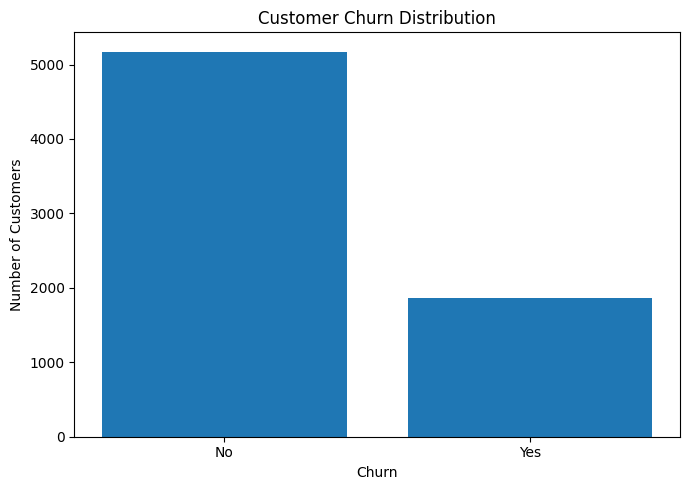

Churn
No     73.46
Yes    26.54
Name: count, dtype: float64


In [0]:
# Visualisation 1: Churn distribution.
churn_counts = df_clean["Churn"].value_counts().reindex(["No", "Yes"])

plt.figure(figsize=(7, 5))
plt.bar(churn_counts.index, churn_counts.values)
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

# The percentage helps us see the degree of class imbalance.
print((churn_counts / churn_counts.sum() * 100).round(2))

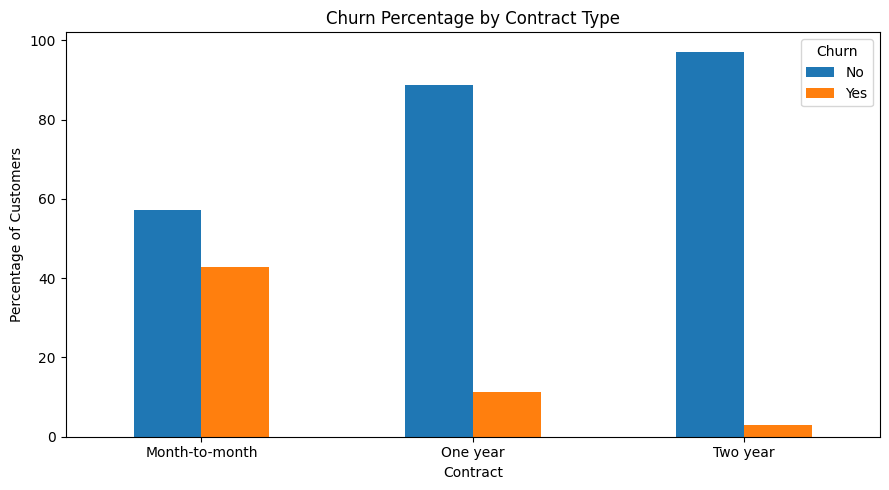

In [0]:
# Visualisation 2: Churn by contract type.
contract_churn = pd.crosstab(
    df_clean["Contract"], df_clean["Churn"], normalize="index"
) * 100

contract_churn.plot(kind="bar", figsize=(9, 5))
plt.title("Churn Percentage by Contract Type")
plt.xlabel("Contract")
plt.ylabel("Percentage of Customers")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.tight_layout()
plt.show()

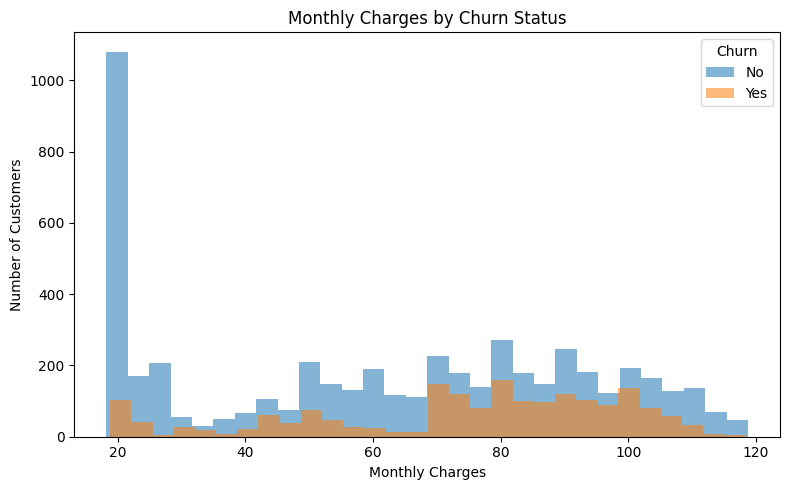

In [0]:
# Visualisation 3: Monthly charges for customers who stayed and churned.
plt.figure(figsize=(8, 5))

for churn_label in ["No", "Yes"]:
    values = df_clean.loc[
        df_clean["Churn"] == churn_label, "MonthlyCharges"
    ].dropna()
    plt.hist(values, bins=30, alpha=0.55, label=churn_label)

plt.title("Monthly Charges by Churn Status")
plt.xlabel("Monthly Charges")
plt.ylabel("Number of Customers")
plt.legend(title="Churn")
plt.tight_layout()
plt.show()

In [0]:
# Summarise selected numeric variables by churn status.
numeric_summary = df_clean.groupby("Churn")[
    ["tenure", "MonthlyCharges", "TotalCharges"]
].mean().round(2)

display(numeric_summary)

tenure,MonthlyCharges,TotalCharges
37.57,61.27,2555.34
17.98,74.44,1531.8


### Step 5: Prepare the data for machine learning

Machine learning algorithms require numeric inputs. We will:
1. Separate the predictors (`X`) from the target (`y`).
2. Exclude the customer identifier.
3. Identify numeric and categorical columns.
4. Impute missing numeric values using the median.
5. Impute missing categorical values using the most frequent value.
6. Convert categorical variables into numeric indicator columns using `OneHotEncoder`.

The preprocessing steps are placed inside a scikit-learn pipeline. This ensures that imputers and encoders are fitted on training folds only during cross-validation, reducing data leakage.

In [0]:
# Separate the target from the predictor columns.
X = df_clean.drop(columns=["Churn", "customerID"])
y = df_clean["Churn"].map({"No": 0, "Yes": 1})

# Identify column types automatically.
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Target mapping: No = 0, Yes = 1")

Numeric features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Target mapping: No = 0, Yes = 1


In [0]:
# Build preprocessing pipelines.
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Apply the correct preprocessing to each column group.
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


### Step 6: Split the data

  **80% training / 20% testing** split (page 7), we reserve 20% of the records for final evaluation.

`stratify=y` preserves approximately the same churn/non-churn proportions in both sets. The test set must remain separate and must not be used to fit or tune the models.

In [0]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

print("\\nTraining target proportions:")
display(y_train.value_counts(normalize=True).rename("Proportion").to_frame())

print("Testing target proportions:")
display(y_test.value_counts(normalize=True).rename("Proportion").to_frame())

Training records: 5634
Testing records: 1409
\nTraining target proportions:


Proportion
0.7346467873624423
0.2653532126375577


Testing target proportions:


Proportion
0.7345635202271115
0.2654364797728886


## Phase 3 – Build the models

### Step 7: Choose the machine learning algorithms

I will compare two ensemble classification algorithms:

- **Random Forest:** combines predictions from many decision trees. We use `class_weight="balanced"` so the model gives additional weight to the less frequent churn class.
- **XGBoost:** builds boosted trees sequentially. We set `scale_pos_weight` using the training class counts to account for the imbalance.



In [0]:
# Calculate the positive-class weight from the training labels only.
negative_count = int((y_train == 0).sum())
positive_count = int((y_train == 1).sum())
scale_pos_weight = negative_count / positive_count

print("Non-churn training records:", negative_count)
print("Churn training records:", positive_count)
print("XGBoost scale_pos_weight:", round(scale_pos_weight, 3))

# Define both classifiers.
rf_model = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1,
    min_samples_leaf=2
)

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.9,
    colsample_bytree=0.9,
    scale_pos_weight=scale_pos_weight,
    eval_metric="logloss",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

print("Random Forest and XGBoost classifiers defined.")

Non-churn training records: 4139
Churn training records: 1495
XGBoost scale_pos_weight: 2.769
Random Forest and XGBoost classifiers defined.


### Step 8: Train the models and perform cross-validation

Five-fold stratified cross-validation is performed on the training data. Each fold uses a different portion of the training set for validation while keeping class proportions broadly consistent.

The preprocessing pipeline is fitted separately inside each fold. We report ROC-AUC for each model, including the mean and standard deviation across folds.

In [0]:
# Create complete pipelines: preprocessing followed by the classifier.
rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", rf_model)
])

xgb_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", xgb_model)
])

# Stratified 5-fold cross-validation on the training data only.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"roc_auc": "roc_auc", "accuracy": "accuracy", "f1": "f1"}

rf_cv = cross_validate(
    rf_pipeline, X_train, y_train,
    cv=cv, scoring=scoring, n_jobs=-1
)

xgb_cv = cross_validate(
    xgb_pipeline, X_train, y_train,
    cv=cv, scoring=scoring, n_jobs=-1
)

cv_results = pd.DataFrame({
    "Model": ["Random Forest", "XGBoost"],
    "Mean CV ROC-AUC": [
        rf_cv["test_roc_auc"].mean(),
        xgb_cv["test_roc_auc"].mean()
    ],
    "ROC-AUC Std": [
        rf_cv["test_roc_auc"].std(),
        xgb_cv["test_roc_auc"].std()
    ],
    "Mean CV Accuracy": [
        rf_cv["test_accuracy"].mean(),
        xgb_cv["test_accuracy"].mean()
    ],
    "Mean CV F1": [
        rf_cv["test_f1"].mean(),
        xgb_cv["test_f1"].mean()
    ]
}).sort_values("Mean CV ROC-AUC", ascending=False)

display(cv_results.round(4))

Model,Mean CV ROC-AUC,ROC-AUC Std,Mean CV Accuracy,Mean CV F1
XGBoost,0.8451,0.0099,0.762,0.6338
Random Forest,0.837,0.0087,0.7875,0.6155


### Fit the final models on the full training set

After cross-validation, fit each pipeline on all training records. The test set remains untouched until the evaluation step.

In [0]:
# Train both models using the complete training dataset.
rf_pipeline.fit(X_train, y_train)
xgb_pipeline.fit(X_train, y_train)

print("Both models have been trained.")

Both models have been trained.


### Step 9: Evaluate the models

 The notebook reports:
- ROC-AUC: ability to rank churn cases above non-churn cases.
- Accuracy: proportion of all predictions that are correct.
- Precision: proportion of predicted churn cases that actually churned.
- Recall: proportion of actual churn cases detected.
- F1-score: harmonic balance of precision and recall.
- Confusion matrix: true negatives, false positives, false negatives and true positives.

The project brief asks for ROC-AUC above 80%. This is a target, not a guaranteed result. We must report the actual measured score honestly.

In [0]:
# Generate predicted class labels and churn probabilities.
rf_predictions = rf_pipeline.predict(X_test)
rf_probabilities = rf_pipeline.predict_proba(X_test)[:, 1]

xgb_predictions = xgb_pipeline.predict(X_test)
xgb_probabilities = xgb_pipeline.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics for both models.
def calculate_metrics(model_name, y_true, predictions, probabilities):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "F1-score": f1_score(y_true, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, probabilities)
    }

test_results = pd.DataFrame([
    calculate_metrics("Random Forest", y_test, rf_predictions, rf_probabilities),
    calculate_metrics("XGBoost", y_test, xgb_predictions, xgb_probabilities)
]).sort_values("ROC-AUC", ascending=False)

display(test_results.round(4))

Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
XGBoost,0.7537,0.5242,0.7807,0.6273,0.8417
Random Forest,0.7842,0.5841,0.6497,0.6152,0.8348


In [0]:
# Display detailed classification reports.
print("RANDOM FOREST – CLASSIFICATION REPORT")
print(classification_report(
    y_test, rf_predictions,
    target_names=["No Churn", "Churn"],
    zero_division=0
))

print("\\nXGBOOST – CLASSIFICATION REPORT")
print(classification_report(
    y_test, xgb_predictions,
    target_names=["No Churn", "Churn"],
    zero_division=0
))

RANDOM FOREST – CLASSIFICATION REPORT
              precision    recall  f1-score   support

    No Churn       0.87      0.83      0.85      1035
       Churn       0.58      0.65      0.62       374

    accuracy                           0.78      1409
   macro avg       0.73      0.74      0.73      1409
weighted avg       0.79      0.78      0.79      1409

\nXGBOOST – CLASSIFICATION REPORT
              precision    recall  f1-score   support

    No Churn       0.90      0.74      0.82      1035
       Churn       0.52      0.78      0.63       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.75      0.77      1409



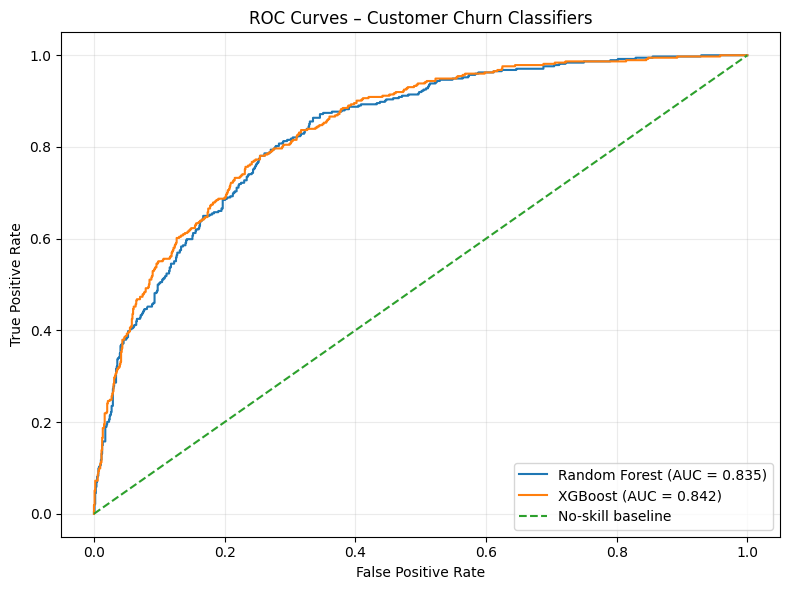

Random Forest ROC-AUC: 0.8348
XGBoost ROC-AUC: 0.8417


In [0]:
# Plot ROC curves for both models on the same chart.
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_probabilities)
xgb_fpr, xgb_tpr, _ = roc_curve(y_test, xgb_probabilities)

rf_auc = roc_auc_score(y_test, rf_probabilities)
xgb_auc = roc_auc_score(y_test, xgb_probabilities)

plt.figure(figsize=(8, 6))
plt.plot(rf_fpr, rf_tpr, label=f"Random Forest (AUC = {rf_auc:.3f})")
plt.plot(xgb_fpr, xgb_tpr, label=f"XGBoost (AUC = {xgb_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="No-skill baseline")

plt.title("ROC Curves – Customer Churn Classifiers")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print(f"Random Forest ROC-AUC: {rf_auc:.4f}")
print(f"XGBoost ROC-AUC: {xgb_auc:.4f}")

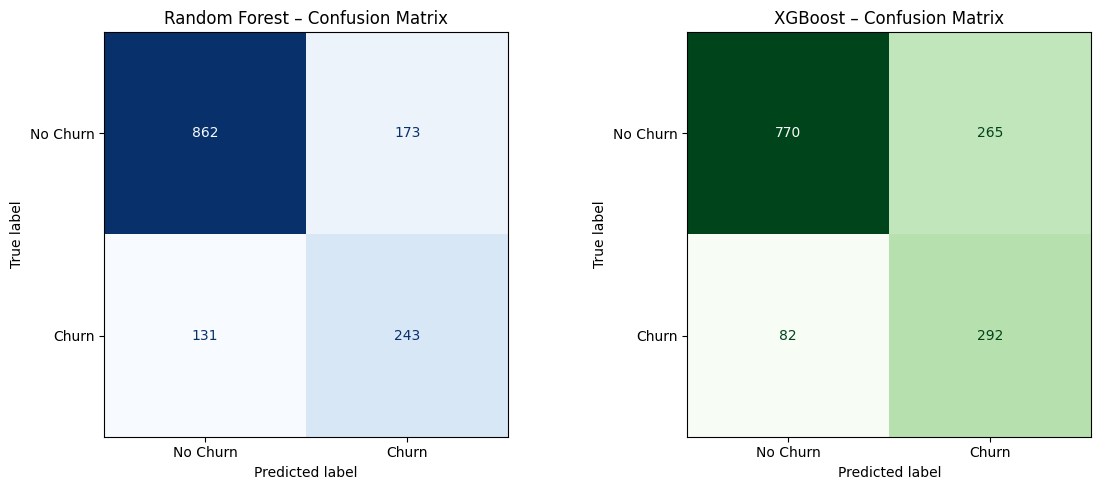

In [0]:
# Plot confusion matrices side by side.
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, rf_predictions,
    display_labels=["No Churn", "Churn"],
    cmap="Blues", ax=axes[0], colorbar=False
)
axes[0].set_title("Random Forest – Confusion Matrix")

ConfusionMatrixDisplay.from_predictions(
    y_test, xgb_predictions,
    display_labels=["No Churn", "Churn"],
    cmap="Greens", ax=axes[1], colorbar=False
)
axes[1].set_title("XGBoost – Confusion Matrix")

plt.tight_layout()
plt.show()

### Step 10: Improve the model and inspect feature importance

Feature importance helps us understand which input variables contributed most to the fitted tree models. We will extract the transformed feature names from the fitted preprocessing pipeline and plot the top 10 features for each model.

Important: feature importance describes model contribution, not proof that a feature causes customer churn. One-hot encoding also means a categorical column can appear as several individual features.

In [0]:
# Retrieve the feature names created by the fitted preprocessing stage.
feature_names = rf_pipeline.named_steps["preprocessor"].get_feature_names_out()

# Get feature importance from each fitted tree model.
rf_importances = rf_pipeline.named_steps["classifier"].feature_importances_
xgb_importances = xgb_pipeline.named_steps["classifier"].feature_importances_

rf_feature_importance = (
    pd.DataFrame({"Feature": feature_names, "Importance": rf_importances})
    .sort_values("Importance", ascending=False)
    .head(10)
)

xgb_feature_importance = (
    pd.DataFrame({"Feature": feature_names, "Importance": xgb_importances})
    .sort_values("Importance", ascending=False)
    .head(10)
)

print("TOP 10 RANDOM FOREST FEATURES")
display(rf_feature_importance)

print("TOP 10 XGBOOST FEATURES")
display(xgb_feature_importance)

TOP 10 RANDOM FOREST FEATURES


Feature,Importance
num__tenure,0.12849407918305944
num__TotalCharges,0.12567151372167273
num__MonthlyCharges,0.09914011997034744
cat__Contract_Month-to-month,0.09277169129909218
cat__OnlineSecurity_No,0.0481606564996969
cat__Contract_Two year,0.044541876572356115
cat__TechSupport_No,0.03834479728532831
cat__InternetService_Fiber optic,0.037677124643806736
cat__PaymentMethod_Electronic check,0.031462893200579885
cat__OnlineBackup_No,0.017800399602417624


TOP 10 XGBOOST FEATURES


Feature,Importance
cat__Contract_Month-to-month,0.39332104
cat__InternetService_Fiber optic,0.097909726
cat__OnlineSecurity_No,0.09542024
cat__InternetService_DSL,0.034542814
cat__Contract_Two year,0.033247143
cat__TechSupport_No,0.029442515
cat__StreamingMovies_Yes,0.027829148
cat__Contract_One year,0.023807973
cat__PaymentMethod_Electronic check,0.018980918
num__tenure,0.016047165


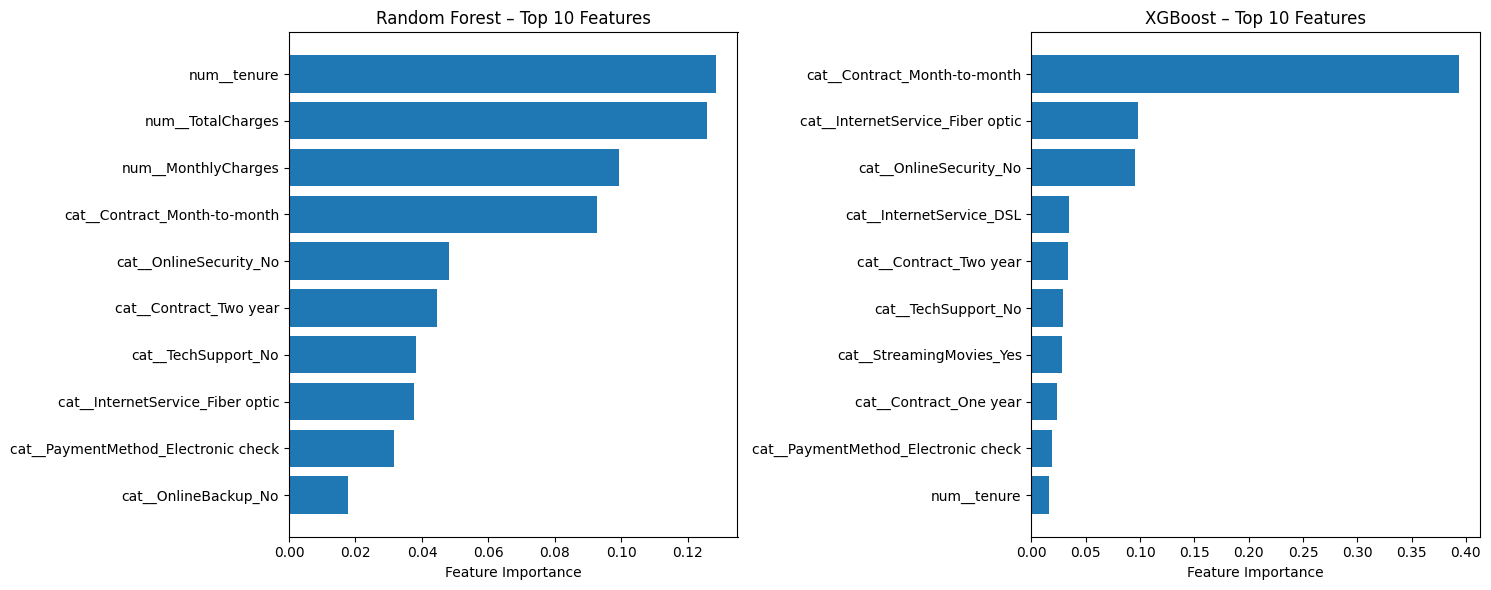

In [0]:
# Visualise the top 10 feature importances for each model.
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

rf_plot = rf_feature_importance.sort_values("Importance")
axes[0].barh(rf_plot["Feature"], rf_plot["Importance"])
axes[0].set_title("Random Forest – Top 10 Features")
axes[0].set_xlabel("Feature Importance")

xgb_plot = xgb_feature_importance.sort_values("Importance")
axes[1].barh(xgb_plot["Feature"], xgb_plot["Importance"])
axes[1].set_title("XGBoost – Top 10 Features")
axes[1].set_xlabel("Feature Importance")

plt.tight_layout()
plt.show()

In [0]:
# Select the model with the higher held-out test ROC-AUC.
best_model_name = test_results.iloc[0]["Model"]
best_auc = test_results.iloc[0]["ROC-AUC"]

print("Best model based on test ROC-AUC:", best_model_name)
print(f"Test ROC-AUC: {best_auc:.4f}")

if best_auc >= 0.80:
    print("The model meets the project's ROC-AUC target of 0.80 or higher.")
else:
    print("The model has not yet reached the 0.80 ROC-AUC target.")
    print("Consider careful hyperparameter tuning and further feature investigation.")

Best model based on test ROC-AUC: XGBoost
Test ROC-AUC: 0.8417
The model meets the project's ROC-AUC target of 0.80 or higher.


## Phase 4 – Operate the model

### Step 11: Deploy the model

The final fitted model could be saved and integrated into a customer-retention dashboard or an internal application. For example, the business could use churn probabilities to create a list of customers who may need follow-up.

The probability output is a risk score, not a certainty that a customer will leave. A business should choose an intervention threshold based on the cost of contacting customers and the cost of losing them.

The following optional cell saves the better-performing fitted pipeline as a reusable file.

In [0]:
# Save the selected fitted pipeline.
import joblib

best_pipeline = rf_pipeline if best_model_name == "Random Forest" else xgb_pipeline
joblib.dump(best_pipeline, "datheon_customer_churn_model.joblib")

print("Saved model: datheon_customer_churn_model.joblib")

Saved model: datheon_customer_churn_model.joblib


### Step 12: Monitor the model

After deployment, the business should:
- Track ROC-AUC, recall, precision and the confusion matrix once actual outcomes become available.
- Monitor changes in customer behaviour and input data (data drift).
- Check whether the proportion of customers churning changes over time.
- Retrain and re-evaluate the model when performance declines or the data changes materially.

